<a href="https://colab.research.google.com/github/iarapineda/Ciencia-y-anal-tica-de-datos-Sep2026/blob/main/Actividad6FE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

### **ACTIVIDAD HECHA INDIVIDUALMENTE**

---

*   NOMBRE: IARA PÉREZ PIINEDA
*   MATRÍCULA: A01705855

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [55]:
# Instalar las bibliotecas necesarias
!pip install category_encoders

In [56]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [57]:
compu_df = pd.read_csv("computer_prices.csv")

compu_df.info()

print("Columnas numéricas:", compu_df.select_dtypes(include="number").shape[1])
print("Columnas de texto:", compu_df.select_dtypes(include="object").shape[1])

display(compu_df.nunique().to_frame("Valores únicos"))

compu_df.drop(columns=["model", "cpu_model"], inplace=True)

print("Dimensiones finales:", compu_df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   model                100000 non-null  object 
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  object 
 5   form_factor          100000 non-null  object 
 6   cpu_brand            100000 non-null  object 
 7   cpu_model            100000 non-null  object 
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  object 
 12  gpu_model            100000 non-null  object 
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb            

,Valores únicos
device_type,2
brand,10
model,99036
release_year,8
os,4
form_factor,10
cpu_brand,3
cpu_model,26971
cpu_tier,6
cpu_cores,12


Dimensiones finales: (100000, 25)


Este conjunto de datos contiene 100,000 registros y 27 columnas, de las cuales 15 son numéricas y 12 son de texto.

Se identificó que las variables model y cpu_model presentan una cardinalidad elevada, con 99,036 y 26,971 valores únicos, respectivamente. Por ello, se eliminaron ambas columnas. Además, parte de la información de cpu_model ya está representada en otras características del procesador, como cpu_tier, cpu_cores y cpu_threads.

Después de esta eliminación, el df conserva 25 columnas para continuar con el análisis.

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

Registros duplicados: 0
Valores faltantes: 0
Estadísticas numéricas


,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.524980,0.797284,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.383450,62.795034,0.00,0.00,65.00,90.00,240.00


Estadísticas categóricas


,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149


Frecuencias de device_type


...

,Frecuencia
storage_type,
NVMe,45059
SSD,24937
HDD,15023
Hybrid,14981


Frecuencias de display_type


,Frecuencia
display_type,
LED,32000
OLED,21910
IPS,17742
Mini-LED,12188
QLED,10069
VA,6091


Frecuencias de wifi


,Frecuencia
wifi,
Wi-Fi 6,46149
Wi-Fi 6E,25923
Wi-Fi 5,19926
Wi-Fi 7,8002


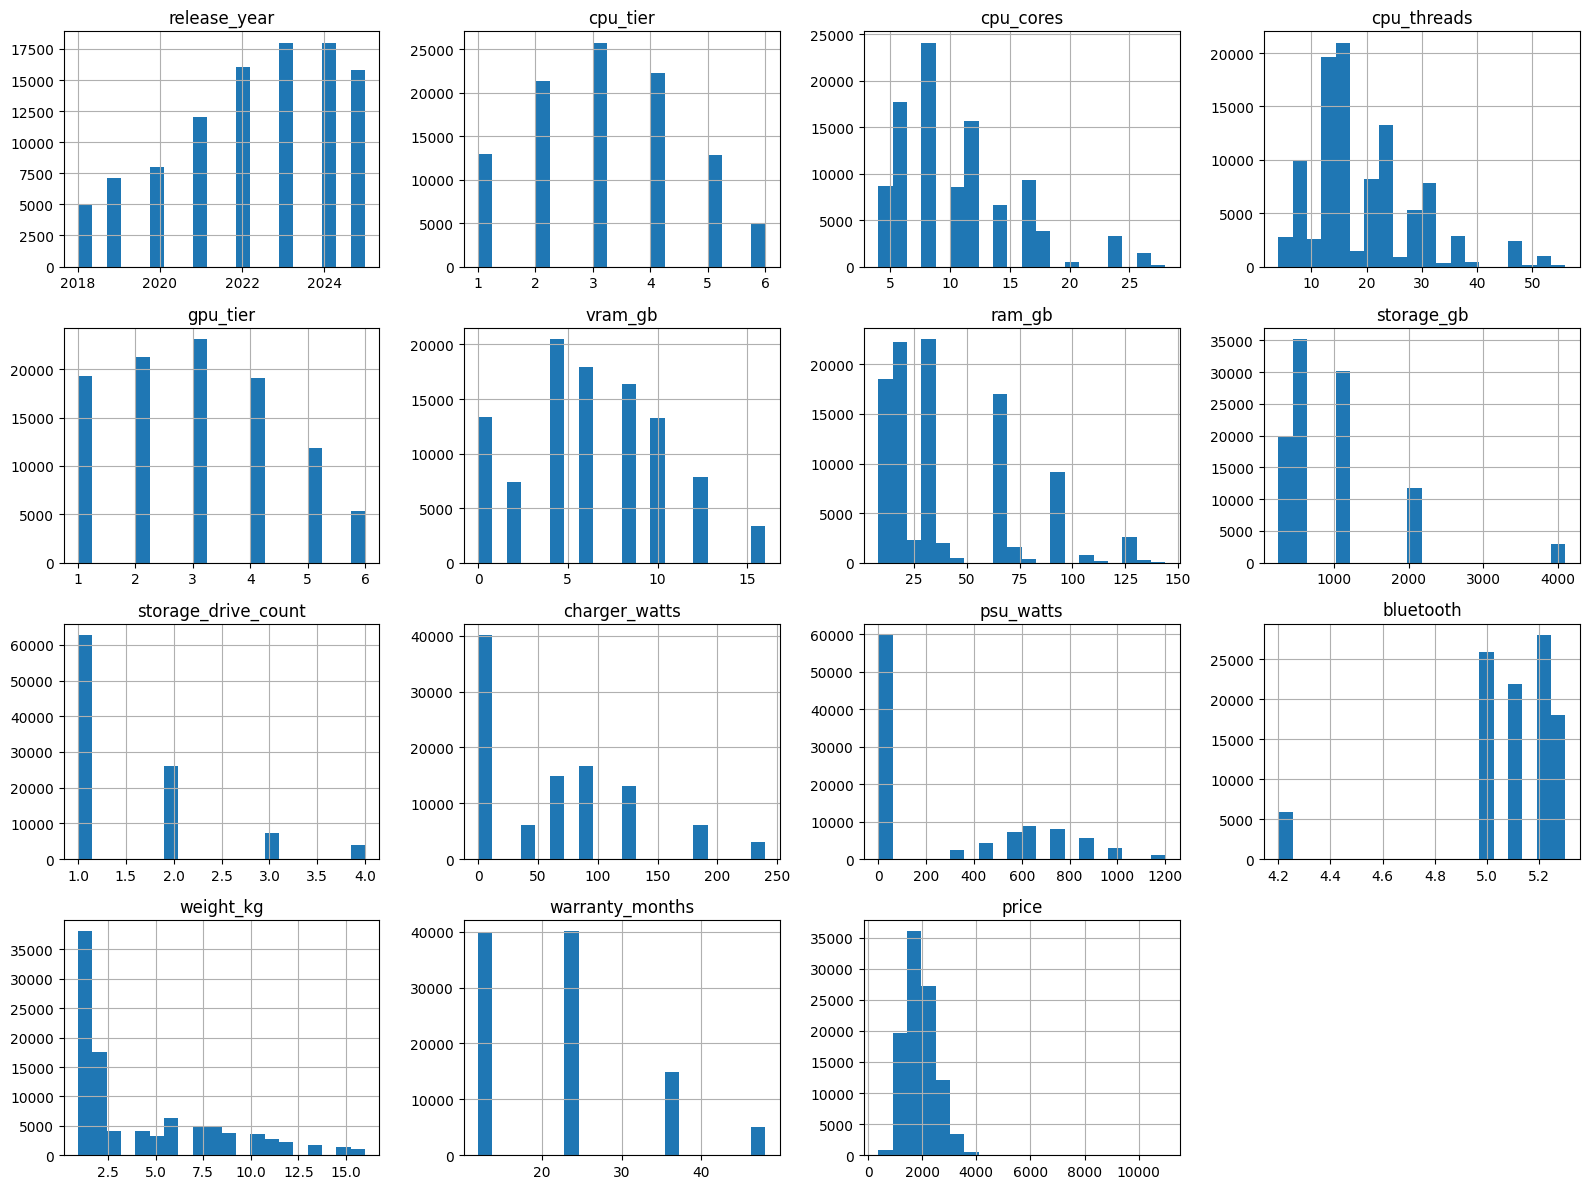

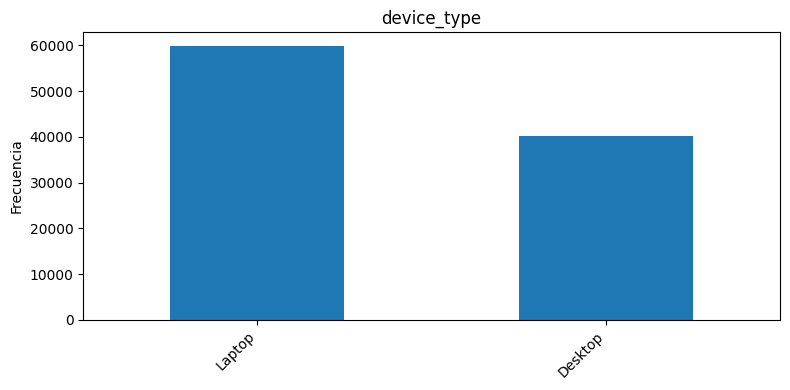

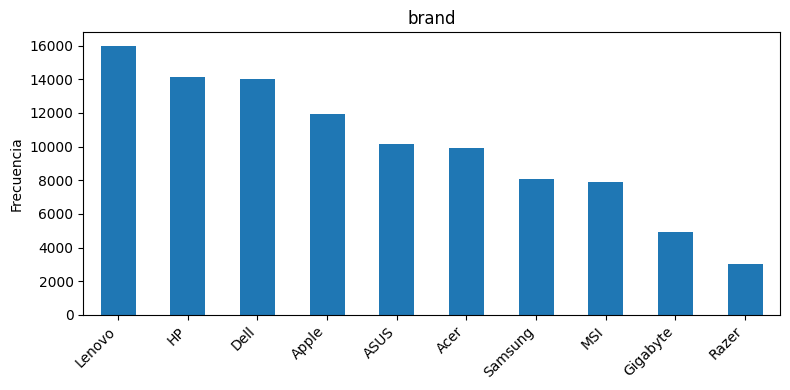

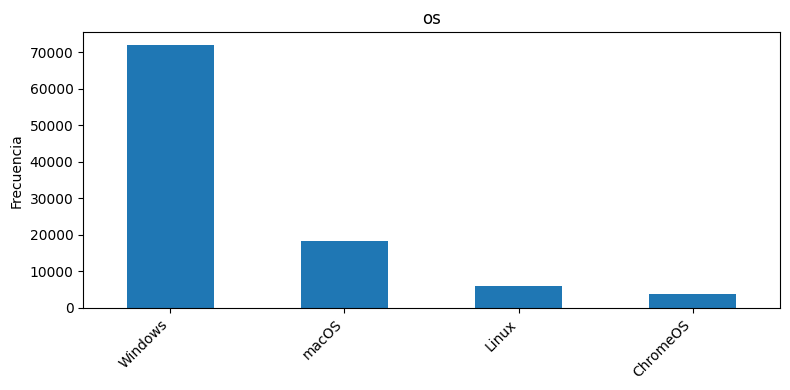

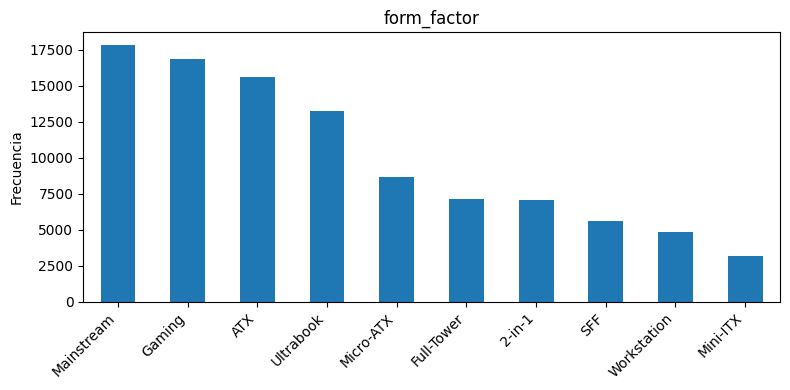

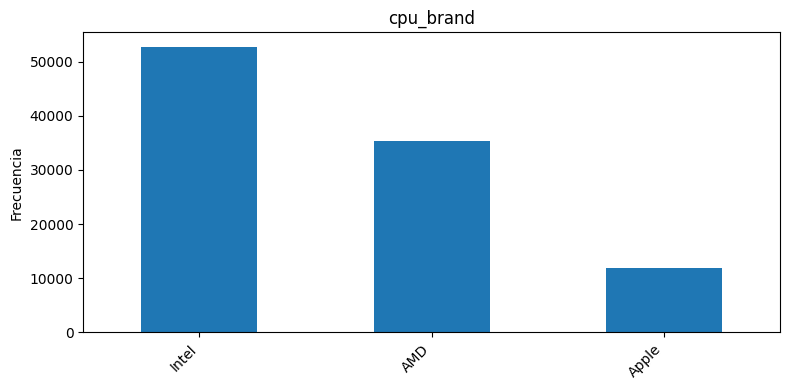

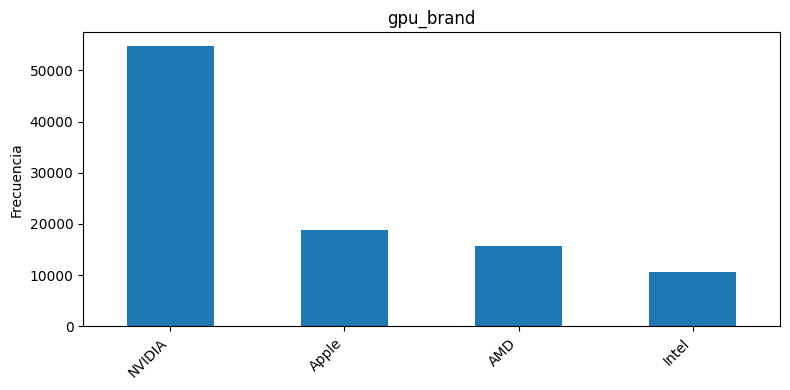

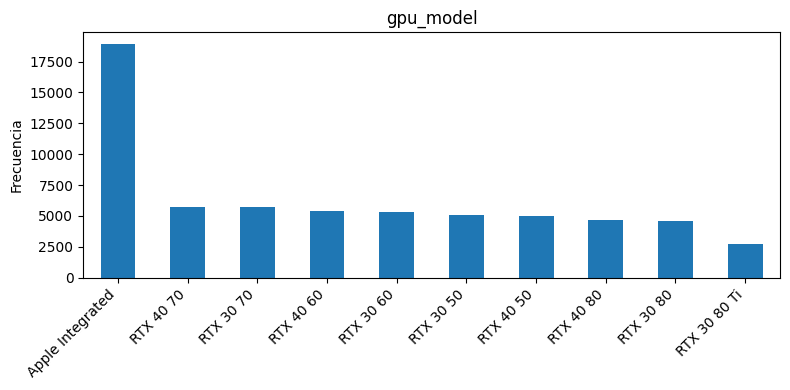

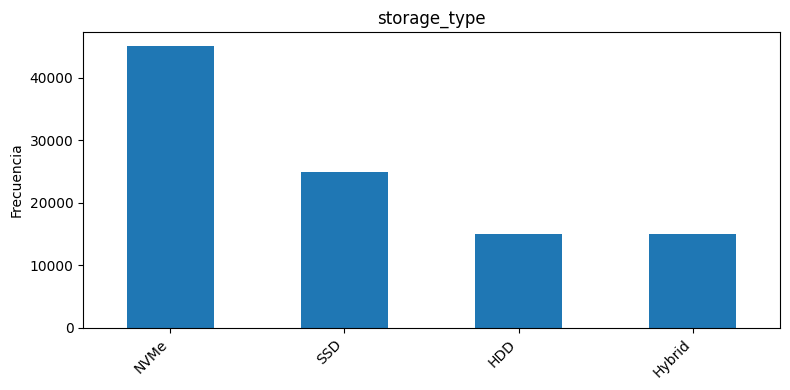

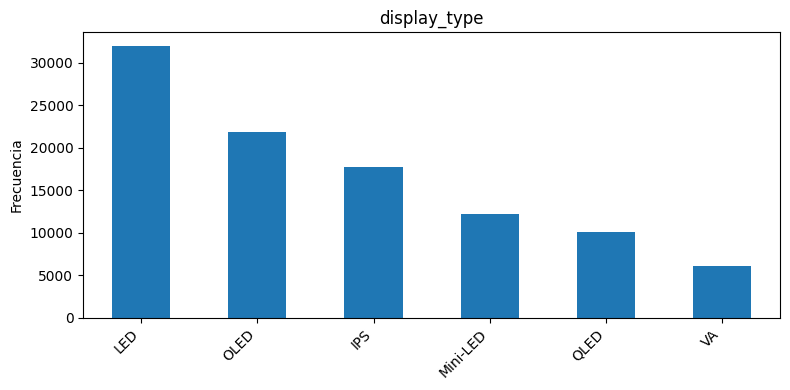

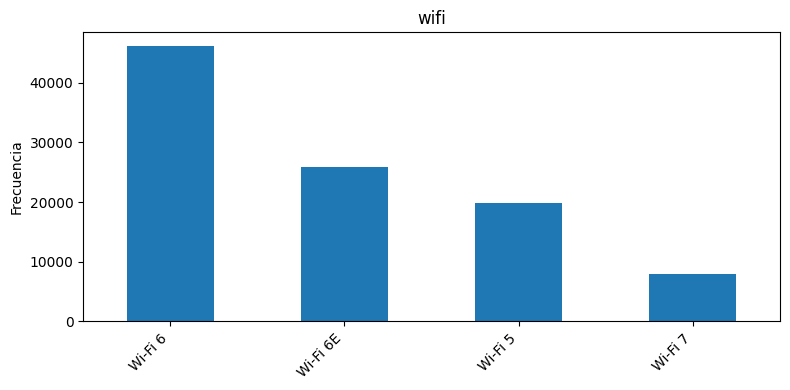

In [58]:

print("Registros duplicados:", compu_df.duplicated().sum())
print("Valores faltantes:", compu_df.isnull().sum().sum())

print("Estadísticas numéricas")
display(compu_df.describe(include="number").T)

print("Estadísticas categóricas")
display(compu_df.describe(include="object").T)

categoricas = compu_df.select_dtypes(include="object")

for columna in categoricas:
    print(f"Frecuencias de {columna}")
    display(compu_df[columna].value_counts().to_frame("Frecuencia"))

compu_df.select_dtypes(include="number").hist(bins=20, figsize=(16, 12))
plt.tight_layout()
plt.show()

for columna in categoricas:
    plt.figure(figsize=(8, 4))
    compu_df[columna].value_counts().head(10).plot(kind="bar")
    plt.title(columna)
    plt.xlabel("")
    plt.ylabel("Frecuencia")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


El conjunto de datos no presenta registros duplicados ni valores faltantes, por lo que no fue necesario realizar operaciones adicionales de limpieza.

Se obtuvieron estadísticas descriptivas de las variables numéricas y categóricas, junto con las tablas de frecuencia correspondientes. Además, se generaron histogramas y diagramas de barras para observar las distribuciones de las características.

Entre los resultados iniciales, se identificó que el precio presenta valores elevados respecto a su promedio, mientras que las variables `charger_watts` y `psu_watts` contienen numerosos registros con valor cero. Estos comportamientos se analizarán con mayor detalle en las siguientes preguntas.

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

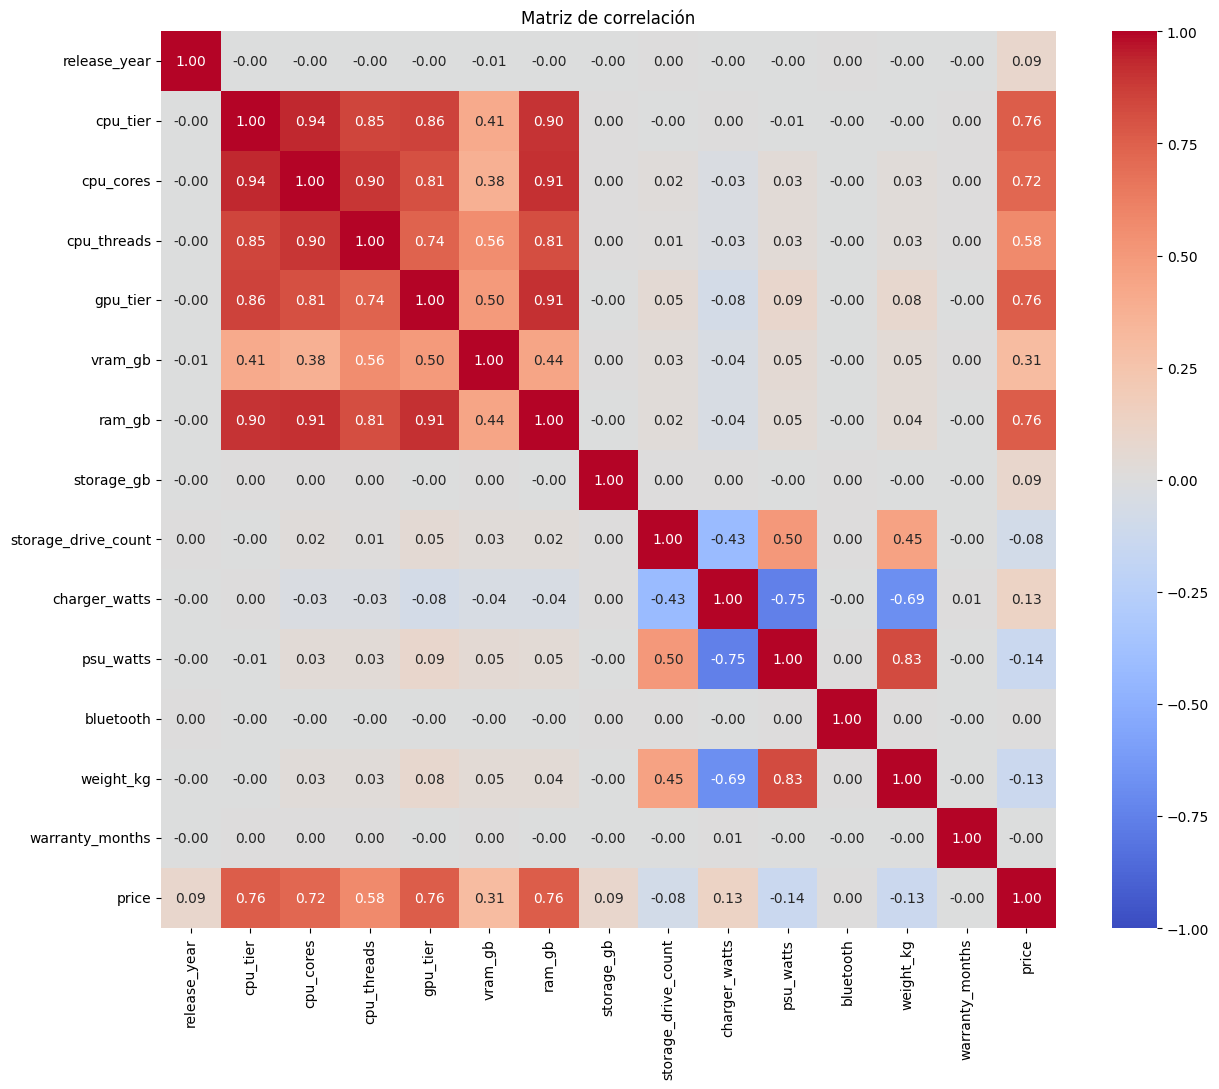

Correlaciones superiores a 0.90:
cpu_tier   cpu_cores    0.937
cpu_cores  ram_gb       0.907
gpu_tier   ram_gb       0.913
dtype: float64
Dimensiones finales: (100000, 23)


In [59]:

correlacion = compu_df.select_dtypes(include="number").corr()

plt.figure(figsize=(13, 11))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

pares = correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool)).stack()

print("Correlaciones superiores a 0.90:")
print(pares[pares > 0.9].round(3))


compu_df.drop(columns=["cpu_cores", "ram_gb"], inplace=True, errors="ignore")


print("Dimensiones finales:", compu_df.shape)


Se generó una matriz de correlación para identificar relaciones entre las variables numéricas. Se encontraron tres pares con correlaciones superiores a 0.90: cpu_tier y cpu_cores (0.937), cpu_cores y ram_gb (0.907), y gpu_tier y ram_gb (0.913).

Se decidió conservar cpu_tier y gpu_tier, ya que representan de manera general el nivel de rendimiento del procesador y la tarjeta gráfica, respectivamente. Por otro lado, se eliminaron cpu_cores y ram_gb para reducir la redundancia entre las características altamente correlacionadas.

Con esta selección, el conjunto de datos pasa de 25 a 23 columnas, conservando variables representativas de la capacidad del hardware.

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

Límites de los intervalos:
[ 0.  4.  6.  8. 16.]


,Cantidad
vram_gb,
0,20757
1,20517
2,17930
3,40796


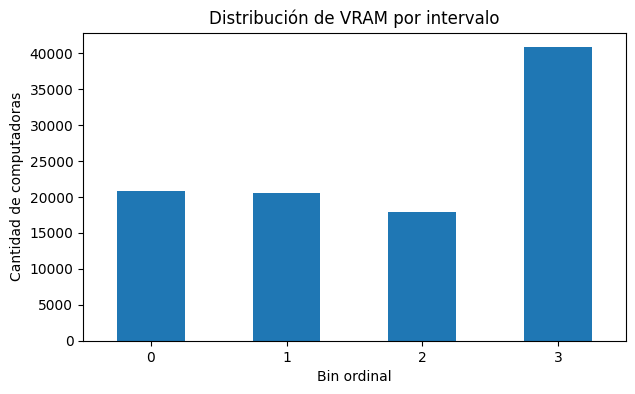

In [60]:

compu_transf = compu_df.copy()

compu_transf["years_since_release"] = date.today().year - compu_transf["release_year"]
compu_transf.drop(columns="release_year", inplace=True)

discretizador = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile", subsample=None)

compu_transf["vram_gb"] = discretizador.fit_transform(compu_transf[["vram_gb"]]).astype(int)

print("Límites de los intervalos:")
print(discretizador.bin_edges_[0])

frecuencias = compu_transf["vram_gb"].value_counts().sort_index()
display(frecuencias.to_frame("Cantidad"))

frecuencias.plot(kind="bar", figsize=(7, 4))
plt.title("Distribución de VRAM por intervalo")
plt.xlabel("Bin ordinal")
plt.ylabel("Cantidad de computadoras")
plt.xticks(rotation=0)
plt.show()


Se creó una copia del dataframe para realizar las transformaciones sin modificar los datos originales. Posteriormente, se generó la variable `years_since_release`, calculando los años transcurridos desde el lanzamiento de cada dispositivo, y se eliminó `release_year`.

Además, se aplicó `KBinsDiscretizer` para agrupar la memoria de video (`vram_gb`) en cuatro intervalos ordinales basados en cuantiles.

La distribución muestra que el intervalo con mayor cantidad de dispositivos corresponde a valores de 8 a 16 GB de VRAM, mientras que los demás contienen menos observaciones. Esto ocurre porque existen valores repetidos y no es posible dividirlos exactamente en grupos de igual frecuencia.

La discretización permite representar la capacidad de memoria de video mediante categorías ordenadas, facilitando su análisis posterior.

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

charger_watts      psu_watts      
                      min  max       min   max
device_type                                   
Desktop                 0    0       300  1200
Laptop                 45  240         0     0

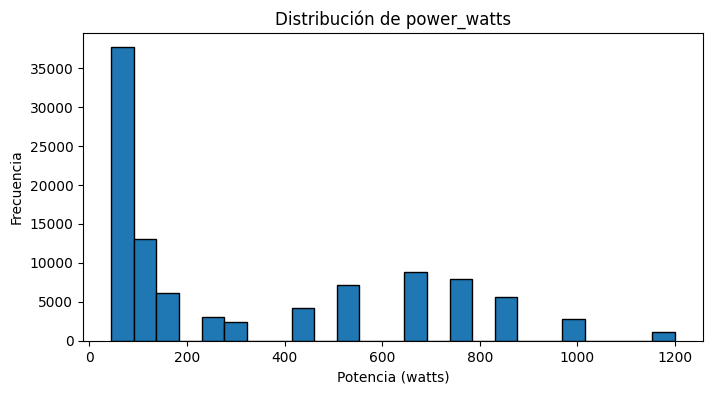

Dimensiones finales: (100000, 22)


In [61]:

display(compu_transf.groupby("device_type")[["charger_watts", "psu_watts"]].agg(["min", "max"]))

compu_transf["power_watts"] = compu_transf["charger_watts"] + compu_transf["psu_watts"]

plt.figure(figsize=(8, 4))
plt.hist(compu_transf["power_watts"], bins=25, edgecolor="black")
plt.title("Distribución de power_watts")
plt.xlabel("Potencia (watts)")
plt.ylabel("Frecuencia")
plt.show()

compu_transf.drop(columns=["charger_watts", "psu_watts"], inplace=True)

print("Dimensiones finales:", compu_transf.shape)


Al analizar las variables `charger_watts` y `psu_watts`, se observó que los valores cero corresponden al tipo de dispositivo. Las laptops utilizan `charger_watts`, mientras que las computadoras de escritorio utilizan `psu_watts`.

Debido a que ambas variables son mutuamente excluyentes, se combinaron en una nueva columna llamada `power_watts`, sumando sus valores. Posteriormente, se eliminaron las columnas originales para evitar información redundante.

El histograma resultante presenta una distribución bimodal, con dos concentraciones de valores asociadas a los diferentes requerimientos de potencia de las laptops y las computadoras de escritorio.

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

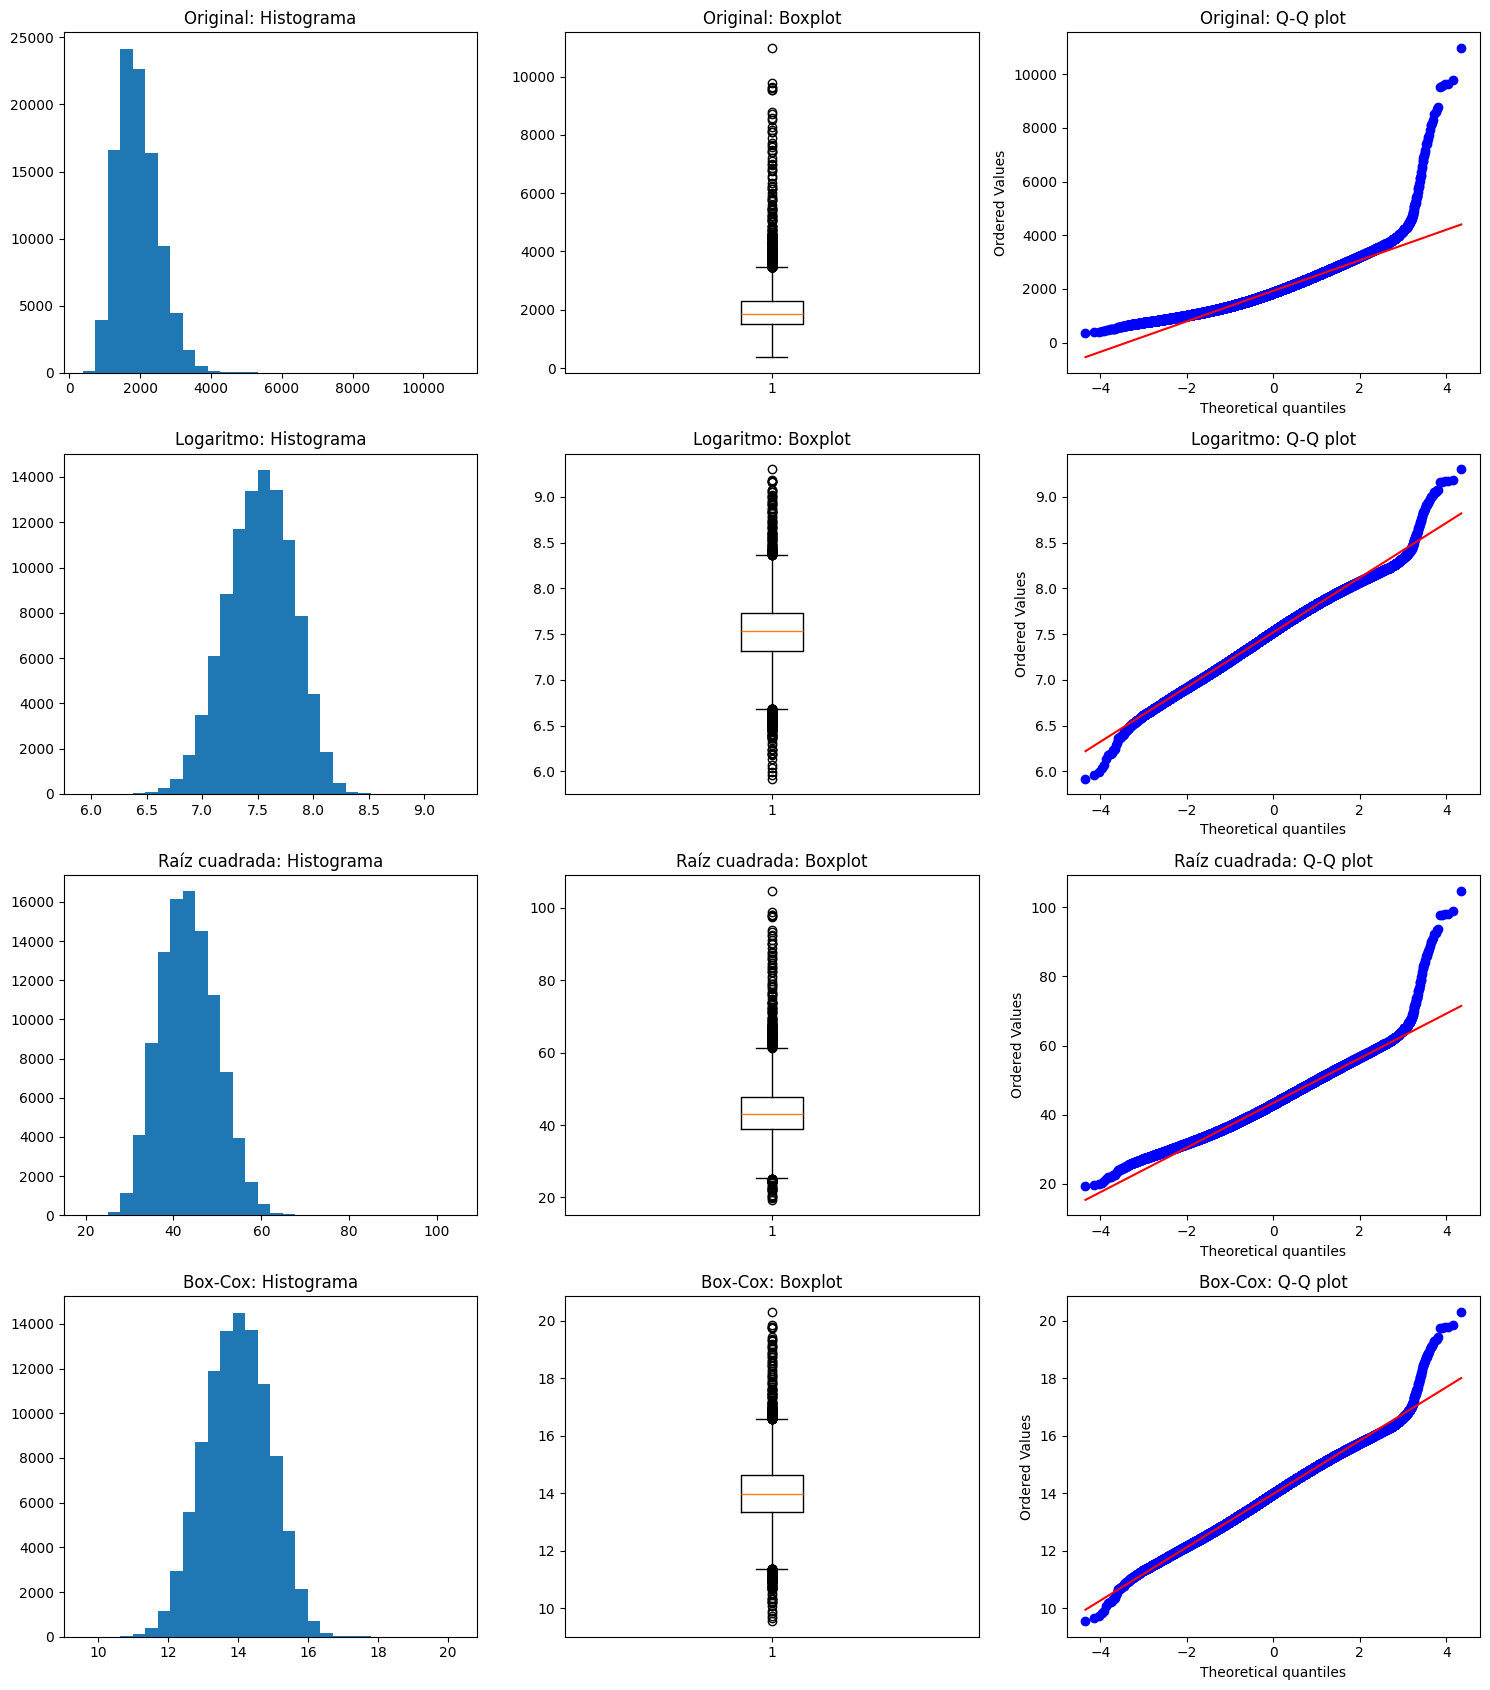

,Transformación,Skew,Outliers
0,Original,0.9866,976
1,Logaritmo,-0.1331,386
2,Raíz cuadrada,0.3323,364
3,Box-Cox,-0.0002,317


,count,mean,std,min,25%,50%,75%,max
weight_kg,100000.0,0.751054,0.475419,-0.085074,0.368418,0.589548,1.264217,1.532097
power_watts,100000.0,3.501907,0.424531,2.826479,3.175932,3.309631,3.978717,4.178945
price,100000.0,13.977771,0.926998,9.552411,13.332762,13.988255,14.634359,20.298790


In [50]:

transformador_log = FunctionTransformer(np.log)
transformador_raiz = FunctionTransformer(np.sqrt)
transformador_boxcox = PowerTransformer(method="box-cox", standardize=False)

precio = compu_transf[["price"]].to_numpy()

precios = {
    "Original": compu_transf["price"],
    "Logaritmo": pd.Series(transformador_log.transform(precio).ravel()),
    "Raíz cuadrada": pd.Series(transformador_raiz.transform(precio).ravel()),
    "Box-Cox": pd.Series(transformador_boxcox.fit_transform(precio).ravel())
}

fig, ejes = plt.subplots(4, 3, figsize=(15, 17))
resultados = []

for i, (nombre, valores) in enumerate(precios.items()):
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)).sum()

    resultados.append([nombre, round(valores.skew(), 4), outliers])

    ejes[i, 0].hist(valores, bins=30)
    ejes[i, 0].set_title(f"{nombre}: Histograma")

    ejes[i, 1].boxplot(valores)
    ejes[i, 1].set_title(f"{nombre}: Boxplot")

    probplot(valores, dist="norm", plot=ejes[i, 2])
    ejes[i, 2].set_title(f"{nombre}: Q-Q plot")

plt.tight_layout()
plt.show()

display(pd.DataFrame(resultados, columns=["Transformación", "Skew", "Outliers"]))

variables_continuas = ["weight_kg", "power_watts", "price"]

transformador_final = PowerTransformer(method="box-cox", standardize=False)
compu_transf[variables_continuas] = transformador_final.fit_transform(compu_transf[variables_continuas])

display(compu_transf[variables_continuas].describe().T)


Se comparó la distribución original de `price` con tres transformaciones: logarítmica, raíz cuadrada y Box-Cox. Para evaluar sus efectos, se generaron histogramas, boxplots y gráficos Q-Q, además de calcular el sesgo y la cantidad de valores atípicos mediante el rango intercuartílico (IQR).

La variable original presentó un sesgo positivo de 0.9866 y 976 valores atípicos. Las tres transformaciones redujeron la asimetría, pero Box-Cox obtuvo los mejores resultados, con un sesgo de -0.0002 y 317 valores atípicos. También mostró una distribución más simétrica y una mayor aproximación a la normalidad, aunque permanecieron algunas desviaciones en los extremos.

Por estos resultados, se seleccionó Box-Cox y se aplicó a las variables continuas `weight_kg`, `power_watts` y `price`, reemplazando sus valores originales. Esta transformación permite reducir la asimetría, aunque no garantiza que todas las variables resulten normales.

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [51]:

numericas = compu_transf.select_dtypes(include="number").columns

escalador = MinMaxScaler()


compu_transf[numericas] = np.clip(escalador.fit_transform(compu_transf[numericas]), 0, 1)


display(compu_transf[numericas].agg(["min", "max"]).T)


,min,max
cpu_tier,0.0,1.0
cpu_threads,0.0,1.0
gpu_tier,0.0,1.0
vram_gb,0.0,1.0
storage_gb,0.0,1.0
storage_drive_count,0.0,1.0
bluetooth,0.0,1.0
weight_kg,0.0,1.0
warranty_months,0.0,1.0
price,0.0,1.0


Se aplicó `MinMaxScaler` a todas las variables numéricas del dataframe para llevar sus valores a una escala común entre 0 y 1.

Esta transformación permite comparar características que originalmente tenían diferentes unidades y rangos, evitando que las variables con valores más grandes tengan una influencia desproporcionada en determinados algoritmos de aprendizaje automático.

Los valores originales fueron reemplazados por sus versiones escaladas, conservando la estructura del dataframe.

8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [52]:

orden_wifi = ["Wi-Fi 5", "Wi-Fi 6", "Wi-Fi 6E", "Wi-Fi 7"]

codificador_wifi = OrdinalEncoder(categories=[orden_wifi])

compu_transf[["wifi"]] = codificador_wifi.fit_transform(compu_transf[["wifi"]])

compu_transf[["wifi"]] = MinMaxScaler().fit_transform(compu_transf[["wifi"]])

display(compu_transf["wifi"].value_counts().sort_index().to_frame("Frecuencia"))


,Frecuencia
wifi,
0.000000,19926
0.333333,46149
0.666667,25923
1.000000,8002


Se aplicó `OrdinalEncoder` a la variable `wifi`, respetando el orden natural de sus categorías: Wi-Fi 5, Wi-Fi 6, Wi-Fi 6E y Wi-Fi 7.

Posteriormente, se utilizó `MinMaxScaler` para transformar los valores codificados a una escala entre 0 y 1, manteniendo el orden de las categorías.

Ambas operaciones se realizaron directamente sobre la columna original `wifi`, conservando una única variable numérica que representa el estándar de conectividad de cada dispositivo.

9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [53]:

codificador_gpu = BinaryEncoder(cols=["gpu_model"])

bin_df = codificador_gpu.fit_transform(compu_transf[["gpu_model"]])

display(bin_df.head())

print("Dimensiones:", bin_df.shape)
print("Valores únicos:", np.unique(bin_df.values))


,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


Dimensiones: (100000, 6)
Valores únicos: [0 1]


Se utilizó `BinaryEncoder` para transformar la variable categórica `gpu_model`, que contiene 49 categorías diferentes.

Esta técnica permite representar los modelos de tarjetas gráficas mediante combinaciones de valores binarios (0 y 1), reduciendo la cantidad de columnas necesarias en comparación con One-Hot Encoding.

El resultado se almacenó en un dataframe independiente llamado `bin_df`, que posteriormente se integrará con `compu_transf`.

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [54]:

categoricas = compu_transf.select_dtypes(include="object").columns.drop("gpu_model")

codificador_ohe = OneHotEncoder(drop="first", sparse_output=False)

ohe_df = pd.DataFrame(
    codificador_ohe.fit_transform(compu_transf[categoricas]),
    columns=codificador_ohe.get_feature_names_out(categoricas),
    index=compu_transf.index
)

compu_transf = pd.concat([
    compu_transf.drop(columns=categoricas.tolist() + ["gpu_model"]),
    bin_df,
    ohe_df
], axis=1)

print("Dimensiones finales:", compu_transf.shape)
print("Columnas categóricas restantes:", compu_transf.select_dtypes(exclude="number").columns.tolist())
print("Todas las columnas entre 0 y 1:", ((compu_transf >= 0) & (compu_transf <= 1)).all().all())

display(compu_transf.describe().T)


Dimensiones finales: (100000, 54)
Columnas categóricas restantes: []
Todas las columnas entre 0 y 1: True


,count,mean,std,min,25%,50%,75%,max
cpu_tier,100000.0,0.430698,0.274635,0.0,0.200000,0.400000,0.600000,1.0
cpu_threads,100000.0,0.295629,0.186893,0.0,0.153846,0.230769,0.384615,1.0
gpu_tier,100000.0,0.398270,0.291929,0.0,0.200000,0.400000,0.600000,1.0
vram_gb,100000.0,0.595883,0.394170,0.0,0.333333,0.666667,1.000000,1.0
storage_gb,100000.0,0.168733,0.201626,0.0,0.066667,0.066667,0.200000,1.0
storage_drive_count,100000.0,0.174993,0.265761,0.0,0.000000,0.000000,0.333333,1.0
wifi,100000.0,0.406670,0.284834,0.0,0.333333,0.333333,0.666667,1.0
bluetooth,100000.0,0.804331,0.223616,0.0,0.727273,0.818182,0.909091,1.0
weight_kg,100000.0,0.517032,0.293982,0.0,0.280423,0.417162,0.834353,1.0
warranty_months,100000.0,0.283343,0.284219,0.0,0.000000,0.333333,0.333333,1.0


Se aplicó `OneHotEncoder` a las variables categóricas restantes, utilizando `drop='first'` para evitar la redundancia entre las categorías. Los resultados se almacenaron en el dataframe `ohe_df`.

Posteriormente, se integraron las variables numéricas transformadas de `compu_transf`, las variables binarias de `bin_df` y las variables codificadas de `ohe_df`, eliminando las columnas categóricas originales.

Finalmente, se utilizó `describe()` para verificar los resultados. El dataframe resultante contiene 100,000 registros y 54 columnas, todas numéricas y con valores dentro del intervalo de 0 a 1.

De esta manera, se obtuvo un conjunto de características transformadas y codificadas, preparado para su utilización posterior en algoritmos de aprendizaje automático.

---

**Declaración de uso de IA**

OpenAI. (2026). *ChatGPT (GPT-6)* [Modelo de lenguaje grande]. Se usó como apoyo para la depuración y explicación del código Python. https://chatgpt.com/

---